## Initial Spinup Analysis: Raw NLDAS and CM
Analysis of model spinup using raw NLDAS forcings and the CM version of the snow model.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from buildforcing.datasets import PNNLSnotel
import os

In [2]:
# Define environment for paths
path_env = 'desktop' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    forcing_path = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
    forcing_path = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
# Run configuration
snotel_site = 'Quemazon'  #Use the Snotel name
spin_up = '100y'
forcings = 's00000000'
forcing_build = 'v0.4.4'
run_config = 'v0'

In [5]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: quemazon


Load forcing:
Forcing is 10 years of NLDAS data that is then looped for the spinup period.

In [7]:
forcing_10yr = xr.open_dataset(os.path.join(forcing_path, site, f'{site}_spinup_s00000000_{forcing_build}.nc'))

In [8]:
forcing_10yr

<xarray.Dataset> Size: 6MB
Dimensions:           (latitude: 1, longitude: 1, time: 87648)
Coordinates:
  * latitude          (latitude) float64 8B 35.92
  * longitude         (longitude) float64 8B -106.4
  * time              (time) object 701kB 1980-10-01 00:00:00 ... 1990-09-30 ...
Data variables:
    Tair              (time, latitude, longitude) float64 701kB ...
    Qair              (time, latitude, longitude) float64 701kB ...
    Psurf             (time, latitude, longitude) float64 701kB ...
    Rainf             (time, latitude, longitude) float64 701kB ...
    Snowf             (time, latitude, longitude) float64 701kB ...
    SWdown            (time, latitude, longitude) float64 701kB ...
    LWdown            (time, latitude, longitude) float64 701kB ...
    Wind              (time, latitude, longitude) float64 701kB ...
    reference_height  (latitude, longitude) int64 8B ...
    canopy_height     (latitude, longitude) float64 8B ...

In [14]:
def get_spinup_forcing(forcing_ds: xr.Dataset, var_name: str) -> pd.Series:
    '''
    Extract a given variable (at a daily timestep) from the forcing dataset and loop it for the 100 year spinup period.
    Return a pandas Series with the looped data.
    '''
    # If 'precip' get sum of 'Rainf' and 'Snowf'
    if var_name == 'precip':
        forcing_ds = forcing_ds.assign(precip=forcing_ds['Rainf'] + forcing_ds['Snowf'])
    
    # Extract the variable data
    var_df = forcing_ds[var_name].isel(latitude=0, longitude=0).to_dataframe()
    data = var_df[var_name] # Extract the variable column
    data.index = data.index.to_datetimeindex()

    # Resample to daily frequency
    data_daily = data.resample('D').mean()

    # Loop the data for 100 years
    model_start_year = data_daily.index[-1].year - 100
    model_start = data_daily.index[0].replace(year=model_start_year)
    model_end = data_daily.index[-1]
    model_index = pd.date_range(start=model_start, end=model_end, freq='D')

    # Loop the data to fill the 100-year period, using 11 groups instead of 10 to ensure full coverage
    looped = pd.concat([data_daily] * 11, ignore_index=True)

    # Ensure the looped data matches the model index length
    looped_values = looped[:len(model_index)].values

    output = pd.Series(looped_values, index=model_index)
    output.name = var_name

    return output
    


In [15]:
test = get_spinup_forcing(forcing_10yr, 'precip')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_13848\3427837780.py:13: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  data.index = data.index.to_datetimeindex()


Load diagnostics

In [16]:
output_folder = os.path.join(output_path,f'{site}/{site}_spinup_{spin_up}_{forcings}_{forcing_build}/history/')

In [17]:
# Find the land daily file name in folder and open
land_daily=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_daily.nc"):
        land_daily = xr.open_dataset(output_folder + filename)
if not land_daily:
    print('Error: no land daily found')

In [18]:
# Find the land month file name in folder and open
land_month=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_month.nc"):
        land_month = xr.open_dataset(output_folder + filename)
if not land_month:
    print('Error: no land daily found')

In [ ]:
land_month

In [ ]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
land_vars_df = pd.DataFrame({
    'dimensions': [land_month[var].dims for var in land_month.data_vars],
    'long_name': [land_month[var].attrs.get('long_name', '') for var in land_month.data_vars],
    'units': [land_month[var].attrs.get('units', '') for var in land_month.data_vars]
}, index=land_month.data_vars)

### Analysis: Vegetation

In [19]:
vegetation_data = land_month[['snow_depth','precip','Tgrnd','height','lai']].isel(grid_index=0).to_dataframe()
vegetation_data.index = vegetation_data.index.to_datetimeindex()

# Drop all extraneous columns
vegetation_data = vegetation_data[['snow_depth','precip','Tgrnd','height','lai']]

C:\Users\clmbn\AppData\Local\Temp\ipykernel_13848\2135545976.py:2: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  vegetation_data.index = vegetation_data.index.to_datetimeindex()


Compare precip to verify that the forcing is correct.

In [20]:
forcing_precip = get_spinup_forcing(forcing_10yr, 'precip')
forcing_precip_month = forcing_precip.resample('MS').mean()

# Shift index forward 15 days to match the land month data
forcing_precip_month.index = forcing_precip_month.index + pd.DateOffset(days=15)

C:\Users\clmbn\AppData\Local\Temp\ipykernel_13848\3427837780.py:13: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  data.index = data.index.to_datetimeindex()


<Axes: >

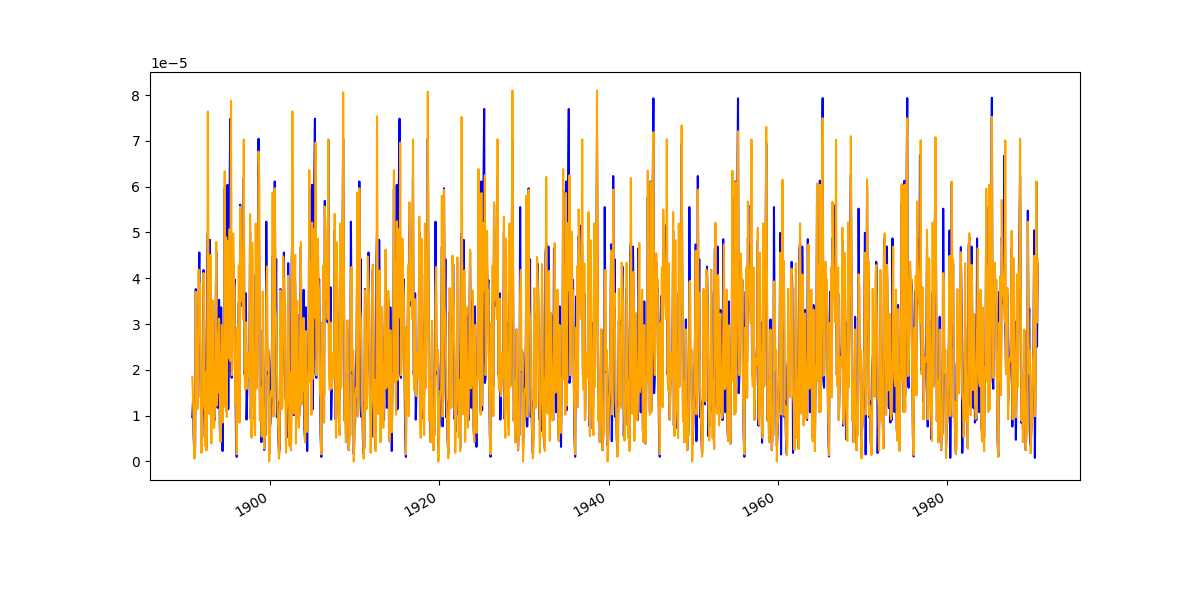

In [21]:
# Plot precip datasets on the same plot
fig, ax = plt.subplots(figsize=(12, 6))
forcing_precip_month.plot(ax=ax, label='Forcing Precipitation', color='blue')
vegetation_data['precip'].plot(ax=ax, label='Vegetation Precipitation', color='orange')

The two datasets should basically be the same, although the land_month data might be averaged differently with a julian calendar. At least they are quite similar.

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

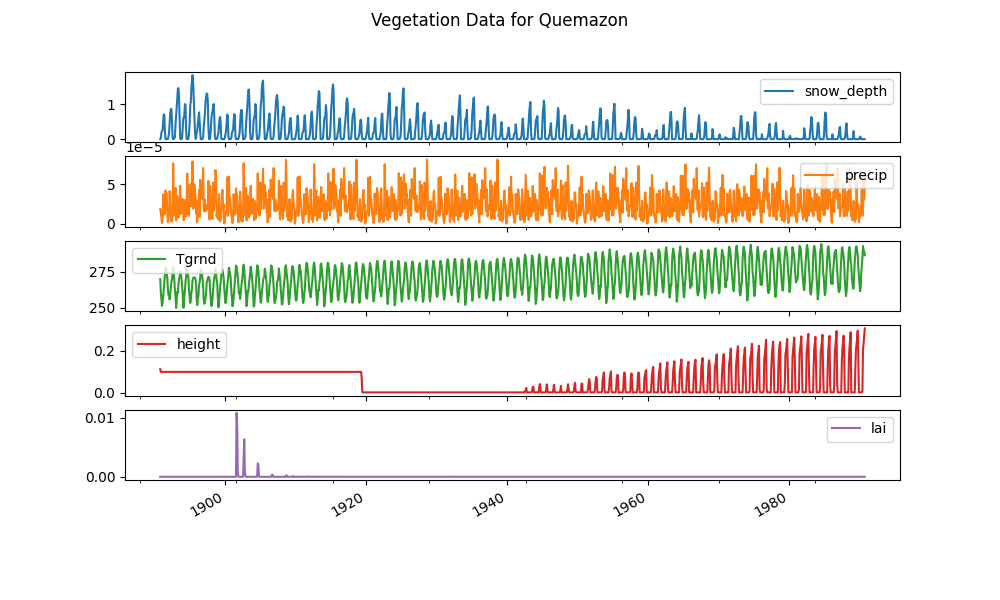

In [22]:
vegetation_data.plot(subplots=True, figsize=(10, 6), title='Vegetation Data for ' + snotel_site)

- Vegetation growth is bizaar for the first 50 years or so, could this be due to soil properties or a model bug?

### Analysis: Soil

In [23]:
# Function for extracting soil data
def extract_soil_data(soil_var) -> pd.DataFrame:
    soil_data = land_month[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

In [24]:
# Extract the soil data at different depths
soil_T = extract_soil_data('soil_T')
soil_liq = extract_soil_data('soil_liq')
soil_ice = extract_soil_data('soil_ice')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_13848\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
C:\Users\clmbn\AppData\Local\Temp\ipykernel_13848\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
C:\Users\clmbn\AppData\Local\Temp\ipykernel_13848\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which us

In [25]:
# Get air temperature from forcing data
Tair = get_spinup_forcing(forcing_10yr, 'Tair')
Tair_month = Tair.resample('MS').mean()

C:\Users\clmbn\AppData\Local\Temp\ipykernel_13848\3427837780.py:13: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  data.index = data.index.to_datetimeindex()


In [26]:
# Merge in ground surface temperature and air temperature
soil_T['Tgrnd'] = vegetation_data['Tgrnd']
soil_T['Tair'] = Tair_month.to_numpy()

# Change soil_T values from Kelvin to Celsius
soil_T = soil_T - 273.15

# Add snow depth to soil_T dataframe
soil_T['snow_depth'] = vegetation_data['snow_depth']

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
      dtype=object)

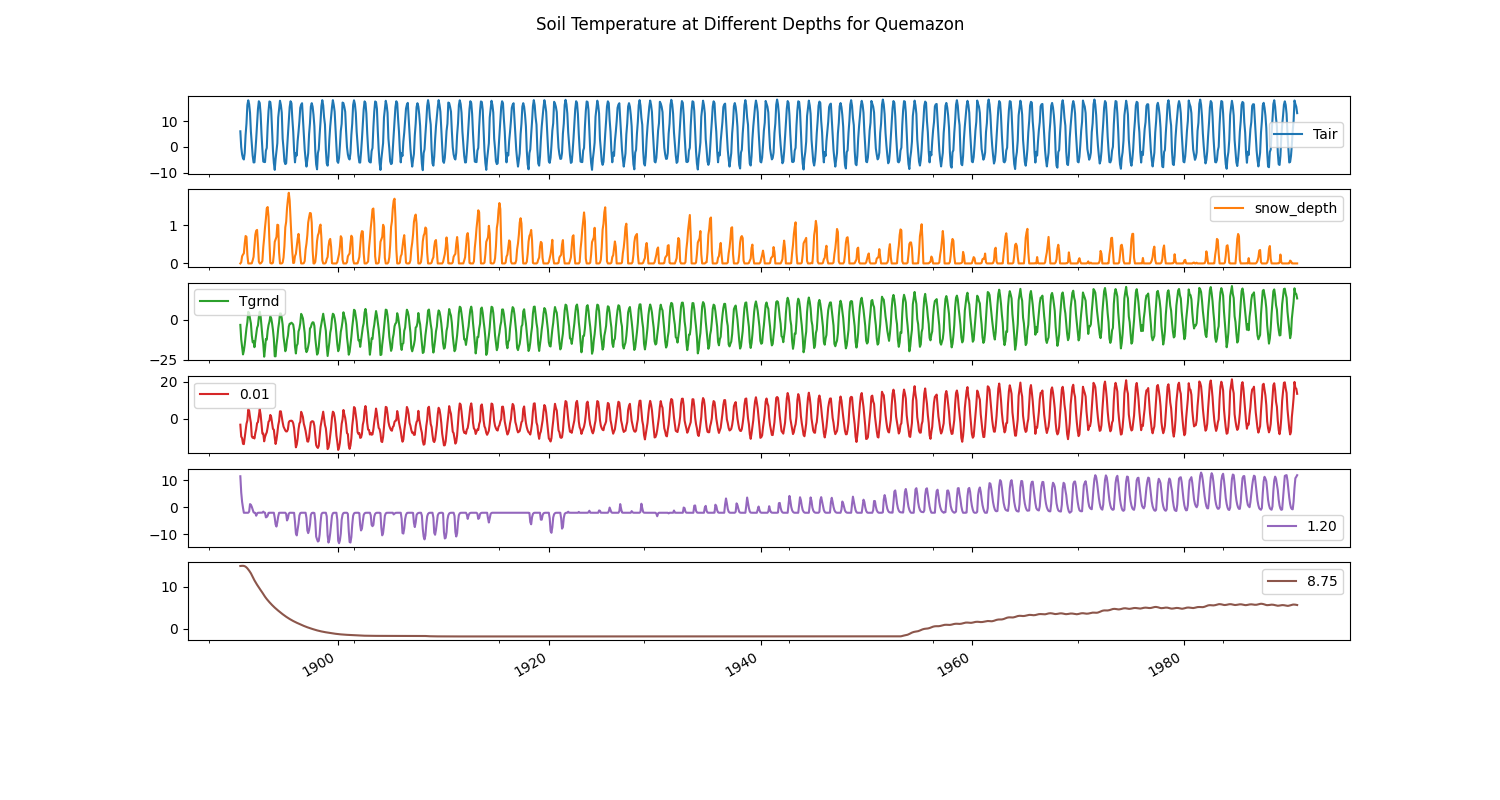

In [27]:
soil_T[['Tair','snow_depth','Tgrnd','0.01','1.20','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Temperature at Different Depths for ' + snotel_site)

This data doesn't make sense. There is almost a meter of snow on the ground early on but the ground surface is at -20 degrees C. This is not possible, the ground surface should be at 0 degrees C if there is snow on the ground.

In [ ]:
soil_ice[['0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Ice at Different Depths for ' + snotel_site)

In [ ]:
# Add precip to soil_liq dataframe
soil_liq['precip'] = vegetation_data['precip']

In [ ]:
soil_liq[['precip','0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Liquid Water at Different Depths for ' + snotel_site)

Liquid water looks fairly normal except deeper where there appears to be permafrost for a long time.